# Lab 1 – Xử lý dữ liệu, hồi quy tuyến tính và điểm F1
Notebook gồm 3 phần:
1. Khám phá dữ liệu: tương quan (correlation), hiệp phương sai (covariance).
2. Hồi quy tuyến tính: hệ số, biểu đồ, $R^2$.
3. Bài toán phân loại: Precision, Recall, **F1-score**, ma trận nhầm lẫn, và áp dụng cho hệ thống đề xuất (F1@K).

> Dữ liệu là **dữ liệu mô phỏng** (sinh bằng `numpy`, `seed=42`) theo dạng bộ Advertising (TV, Radio, Newspaper → Sales), nên notebook chạy độc lập, không cần file CSV.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(42)

n = 200
TV        = rng.uniform(0, 300, n)
Radio     = rng.uniform(0, 50, n)
Newspaper = 0.3 * Radio + rng.uniform(0, 60, n)          # hơi tương quan với Radio
Sales = 3.0 + 0.045 * TV + 0.19 * Radio + 0.0 * Newspaper + rng.normal(0, 1.6, n)

df = pd.DataFrame({'TV': TV, 'Radio': Radio, 'Newspaper': Newspaper, 'Sales': Sales}).round(2)
df.head()

,TV,Radio,Newspaper,Sales
0,232.19,38.87,29.78,22.83
1,131.66,48.59,69.68,17.75
2,257.58,25.04,54.39,19.93
3,209.21,7.19,8.79,9.93
4,28.25,0.70,60.03,2.55


In [2]:
print(df.shape)
df.describe()

(200, 4)


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,148.160900,24.961250,37.180200,14.307100
std,84.693679,14.419848,18.346477,5.077143
min,2.210000,0.620000,0.620000,2.550000
25%,75.665000,11.837500,21.382500,10.817500
50%,143.700000,25.275000,38.405000,14.280000
75%,224.175000,38.330000,52.742500,17.942500
max,297.710000,49.330000,71.050000,27.270000


## 1. Correlation (tương quan)

Hệ số tương quan Pearson giữa hai biến $X, Y$:

$$ r_{XY} = \frac{\operatorname{cov}(X,Y)}{\sigma_X \, \sigma_Y} = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\,\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}} , \qquad -1 \le r \le 1 $$

- $r \approx 1$: tương quan thuận mạnh; $r \approx -1$: nghịch mạnh; $r \approx 0$: gần như không có quan hệ **tuyến tính**.

In [3]:
df[['TV', 'Radio', 'Newspaper', 'Sales']].corr()

,TV,Radio,Newspaper,Sales
TV,1.000000,-0.025950,0.050487,0.756971
Radio,-0.025950,1.000000,0.300666,0.543173
Newspaper,0.050487,0.300666,1.000000,0.178343
Sales,0.756971,0.543173,0.178343,1.000000


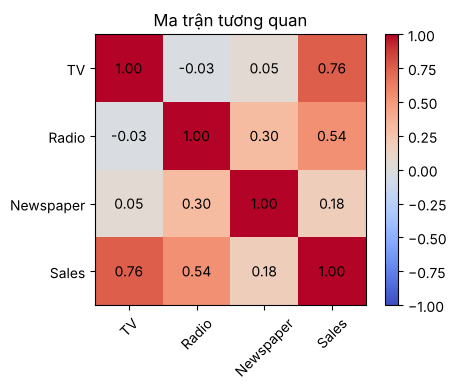

In [4]:
# Biểu đồ nhiệt (heatmap) của ma trận tương quan
corr = df.corr()
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(im); ax.set_title('Ma trận tương quan'); plt.tight_layout(); plt.show()

## 2. Covariance (hiệp phương sai)

$$ \operatorname{cov}(X,Y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y}) $$

Khác với correlation, covariance **phụ thuộc đơn vị đo** nên khó so sánh giữa các cặp biến.

In [5]:
df[['TV', 'Radio', 'Newspaper']].cov()

,TV,Radio,Newspaper
TV,7173.019275,-31.691903,78.448498
Radio,-31.691903,207.932013,79.542225
Newspaper,78.448498,79.542225,336.593231


In [6]:
# Kiểm tra công thức bằng tay với cặp (TV, Sales)
x, y = df['TV'].values, df['Sales'].values
cov_manual = ((x - x.mean()) * (y - y.mean())).sum() / (len(x) - 1)
r_manual = cov_manual / (x.std(ddof=1) * y.std(ddof=1))
print('cov(TV, Sales) tay   :', round(cov_manual, 4), '| pandas:', round(df['TV'].cov(df['Sales']), 4))
print('corr(TV, Sales) tay  :', round(r_manual, 4),   '| pandas:', round(df['TV'].corr(df['Sales']), 4))

cov(TV, Sales) tay   : 325.499 | pandas: 325.499
corr(TV, Sales) tay  : 0.757 | pandas: 0.757


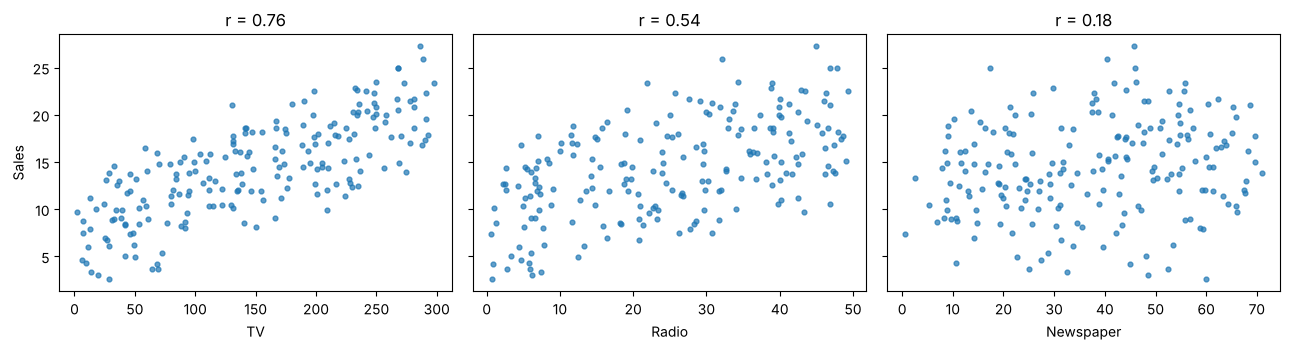

In [7]:
# Biểu đồ phân tán từng biến với Sales
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, col in zip(axes, ['TV', 'Radio', 'Newspaper']):
    ax.scatter(df[col], df['Sales'], s=12, alpha=0.7)
    ax.set_xlabel(col); ax.set_title(f"r = {df[col].corr(df['Sales']):.2f}")
axes[0].set_ylabel('Sales'); plt.tight_layout(); plt.show()

## 3. Hồi quy tuyến tính (Linear Regression)

Mô hình:

$$ \hat{y} = \beta_0 + \beta_1\,\text{TV} + \beta_2\,\text{Radio} + \beta_3\,\text{Newspaper} $$

Hệ số tìm bằng bình phương tối thiểu (OLS):

$$ \hat{\boldsymbol\beta} = \arg\min_{\boldsymbol\beta}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2 = (X^{\top}X)^{-1}X^{\top}y $$

In [8]:
features = ['TV', 'Radio', 'Newspaper']
X_train, X_test, y_train, y_test = train_test_split(
    df[features], df['Sales'], test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
print('Intercept (beta_0):', round(model.intercept_, 4))

df_coef = pd.DataFrame({'features': features, 'coef': model.coef_})
df_coef

Intercept (beta_0): 2.7388


,features,coef
0,TV,0.045711
1,Radio,0.205021
2,Newspaper,-0.009750


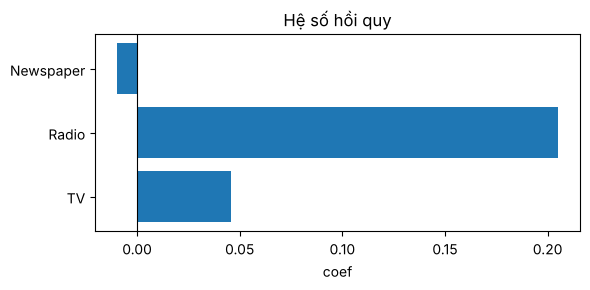

In [9]:
# Biểu đồ hệ số (coefficients)
plt.figure(figsize=(6, 3))
plt.barh(y=df_coef['features'], width=df_coef['coef'], color='tab:blue')
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('coef'); plt.title('Hệ số hồi quy'); plt.tight_layout(); plt.show()

Nhận xét: `TV` và `Radio` có hệ số dương rõ rệt, `Newspaper` gần 0 — khớp với cách dữ liệu được sinh
(Newspaper chỉ tương quan với Sales gián tiếp qua Radio).

## 4. $R^2$ và RMSE

$$ R^2 = 1 - \frac{\sum_i (y_i-\hat{y}_i)^2}{\sum_i (y_i-\bar{y})^2} = 1-\frac{SS_{res}}{SS_{tot}}, \qquad \text{RMSE}=\sqrt{\frac{1}{n}\sum_i (y_i-\hat{y}_i)^2} $$

In [10]:
y_pred = model.predict(X_test)
ss_res = ((y_test - y_pred) ** 2).sum()
ss_tot = ((y_test - y_test.mean()) ** 2).sum()
print('R^2 (công thức tay):', round(1 - ss_res / ss_tot, 4))
print('R^2 (sklearn)      :', round(r2_score(y_test, y_pred), 4))
print('RMSE               :', round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))

R^2 (công thức tay): 0.8995
R^2 (sklearn)      : 0.8995
RMSE               : 1.5853


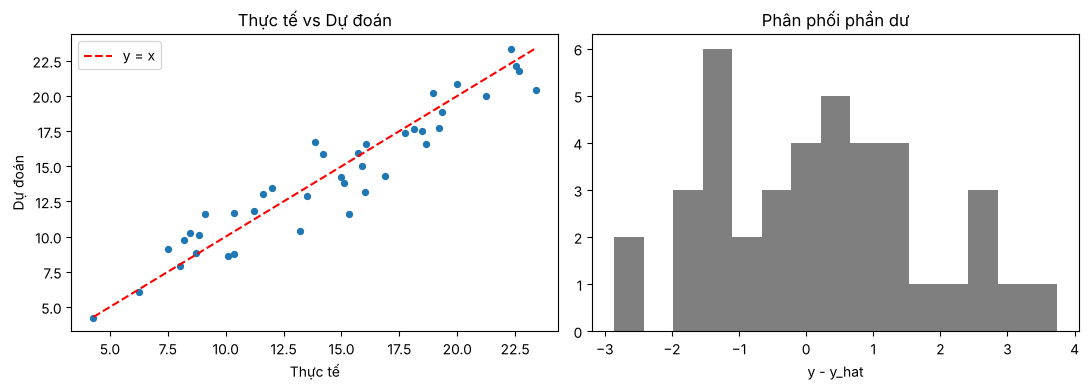

In [11]:
# Mô phỏng: giá trị thực vs dự đoán, và phần dư (residual)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, y_pred, s=18)
lo, hi = y_test.min(), y_test.max()
axes[0].plot([lo, hi], [lo, hi], 'r--', label='y = x')
axes[0].set_xlabel('Thực tế'); axes[0].set_ylabel('Dự đoán'); axes[0].legend(); axes[0].set_title('Thực tế vs Dự đoán')
axes[1].hist(y_test - y_pred, bins=15, color='tab:gray')
axes[1].set_title('Phân phối phần dư'); axes[1].set_xlabel('y - y_hat')
plt.tight_layout(); plt.show()

## 5. Precision, Recall và F1-score

Với bài toán phân loại nhị phân, từ ma trận nhầm lẫn (TP, FP, FN, TN):

$$ \text{Precision}=\frac{TP}{TP+FP}, \qquad \text{Recall}=\frac{TP}{TP+FN} $$

$$ F_1 = \frac{2\,P\,R}{P+R} = \frac{2\,TP}{2\,TP+FP+FN} $$

$F_1$ là **trung bình điều hòa** của Precision và Recall: chỉ cao khi **cả hai** cùng cao. Tổng quát:

$$ F_\beta = (1+\beta^2)\,\frac{P\,R}{\beta^2 P + R} $$

Ví dụ: biến đổi bài toán thành "chiến dịch bán chạy" — nhãn $=1$ nếu `Sales` cao hơn trung vị.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, classification_report

y_cls = (df['Sales'] > df['Sales'].median()).astype(int)
Xtr, Xte, ytr, yte = train_test_split(df[features], y_cls, test_size=0.3, random_state=42, stratify=y_cls)

clf = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
pred = clf.predict(Xte)

tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print(f'TP={tp}  FP={fp}  FN={fn}  TN={tn}')

P = tp / (tp + fp); R = tp / (tp + fn)
F1 = 2 * P * R / (P + R)
print(f'Precision (tay) = {P:.4f} | sklearn = {precision_score(yte, pred):.4f}')
print(f'Recall    (tay) = {R:.4f} | sklearn = {recall_score(yte, pred):.4f}')
print(f'F1        (tay) = {F1:.4f} | sklearn = {f1_score(yte, pred):.4f}')

TP=27  FP=4  FN=3  TN=26
Precision (tay) = 0.8710 | sklearn = 0.8710
Recall    (tay) = 0.9000 | sklearn = 0.9000
F1        (tay) = 0.8852 | sklearn = 0.8852


In [13]:
print(classification_report(yte, pred, target_names=['Sales thấp', 'Sales cao']))

              precision    recall  f1-score   support

  Sales thấp       0.90      0.87      0.88        30
   Sales cao       0.87      0.90      0.89        30

    accuracy                           0.88        60
   macro avg       0.88      0.88      0.88        60
weighted avg       0.88      0.88      0.88        60


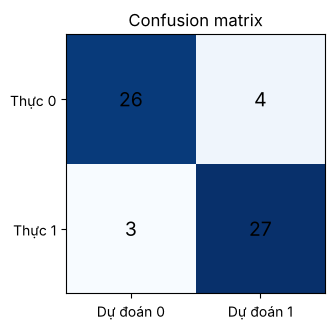

In [14]:
# Vẽ ma trận nhầm lẫn
cm = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(4, 3.4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Dự đoán 0', 'Dự đoán 1'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['Thực 0', 'Thực 1'])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14)
ax.set_title('Confusion matrix'); plt.tight_layout(); plt.show()

### Minh họa: vì sao dùng trung bình điều hòa thay vì trung bình cộng?
Nếu một mô hình đoán "dương" cho **mọi** mẫu thì Recall $=1$ nhưng Precision rất thấp. Trung bình cộng vẫn trông "ổn", còn $F_1$ phạt nặng.

Đoán dương cho tất cả (P=0.5, R=1): F1 = 0.6667 | TB cộng = 0.75


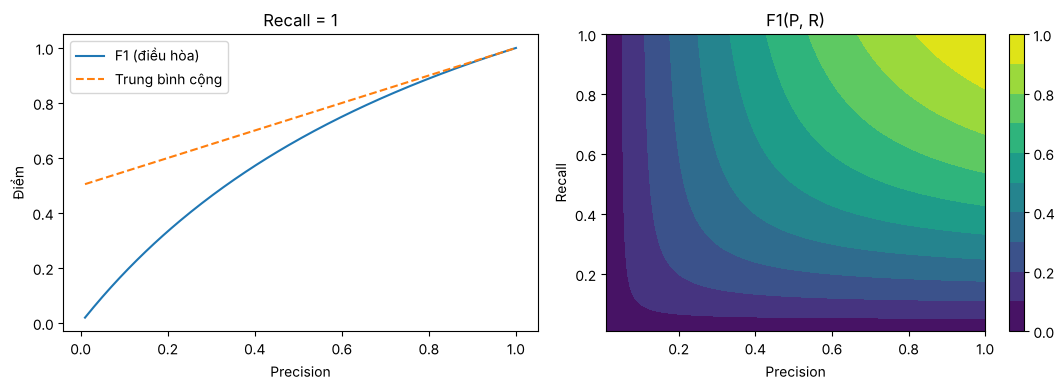

In [15]:
P_grid = np.linspace(0.01, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) F1 vs trung bình cộng khi Recall = 1
R_fix = 1.0
axes[0].plot(P_grid, 2 * P_grid * R_fix / (P_grid + R_fix), label='F1 (điều hòa)')
axes[0].plot(P_grid, (P_grid + R_fix) / 2, '--', label='Trung bình cộng')
axes[0].set_xlabel('Precision'); axes[0].set_ylabel('Điểm'); axes[0].set_title('Recall = 1')
axes[0].legend()

# (b) Đường đồng mức F1 theo (P, R)
PP, RR = np.meshgrid(np.linspace(0.01, 1, 200), np.linspace(0.01, 1, 200))
cs = axes[1].contourf(PP, RR, 2 * PP * RR / (PP + RR), levels=10, cmap='viridis')
fig.colorbar(cs, ax=axes[1]); axes[1].set_xlabel('Precision'); axes[1].set_ylabel('Recall')
axes[1].set_title('F1(P, R)')
plt.tight_layout(); plt.show()

print('Đoán dương cho tất cả (P=0.5, R=1): F1 =', round(2*0.5*1/(0.5+1), 4), '| TB cộng =', 0.75)

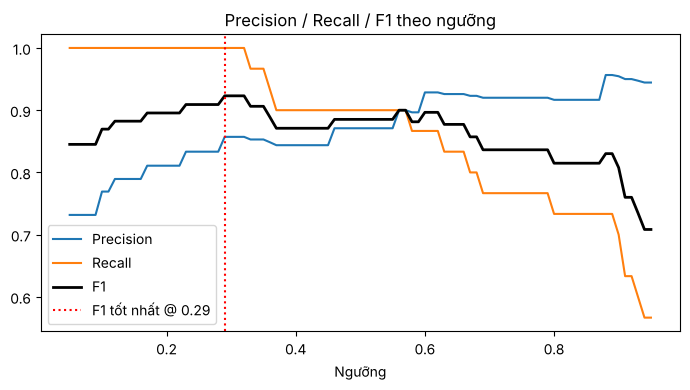

In [16]:
# Đánh đổi Precision-Recall khi đổi ngưỡng quyết định
proba = clf.predict_proba(Xte)[:, 1]
ths = np.linspace(0.05, 0.95, 91)
Ps, Rs, Fs = [], [], []
for t in ths:
    p = (proba >= t).astype(int)
    Ps.append(precision_score(yte, p, zero_division=0))
    Rs.append(recall_score(yte, p))
    Fs.append(f1_score(yte, p))

plt.figure(figsize=(7, 4))
plt.plot(ths, Ps, label='Precision'); plt.plot(ths, Rs, label='Recall'); plt.plot(ths, Fs, 'k', lw=2, label='F1')
best = ths[int(np.argmax(Fs))]
plt.axvline(best, color='r', ls=':', label=f'F1 tốt nhất @ {best:.2f}')
plt.xlabel('Ngưỡng'); plt.legend(); plt.title('Precision / Recall / F1 theo ngưỡng'); plt.tight_layout(); plt.show()

## 6. Áp dụng cho hệ thống đề xuất: Precision@K, Recall@K, F1@K

Với mỗi người dùng, mô hình trả về danh sách top-$K$ sản phẩm; tập sản phẩm người dùng thực sự mua/thêm giỏ trong cửa sổ đánh giá là $\text{Rel}_u$.

$$ P@K = \frac{|\text{Top}_K \cap \text{Rel}_u|}{K}, \qquad R@K = \frac{|\text{Top}_K \cap \text{Rel}_u|}{|\text{Rel}_u|}, \qquad F1@K = \frac{2\,P@K\,R@K}{P@K+R@K} $$

Kết quả báo cáo là trung bình trên các người dùng có $|\text{Rel}_u|>0$.
Ví dụ dưới đây là **dữ liệu giả lập nhỏ** chỉ để minh họa công thức (không phải kết quả của đồ án).

In [17]:
def prf_at_k(recommended, relevant, k):
    top = list(recommended)[:k]
    hit = len(set(top) & set(relevant))
    p = hit / k
    r = hit / len(relevant) if relevant else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    return p, r, f1

# 3 người dùng giả lập: danh sách gợi ý (đã xếp hạng) và tập sản phẩm thực sự quan tâm
recs = {'u1': ['A', 'B', 'C', 'D', 'E'],
        'u2': ['F', 'A', 'G', 'H', 'I'],
        'u3': ['J', 'K', 'L', 'M', 'N']}
rel  = {'u1': {'B', 'E', 'Z'},
        'u2': {'A'},
        'u3': {'X', 'Y'}}

K = 5
rows = []
for u in recs:
    p, r, f = prf_at_k(recs[u], rel[u], K)
    rows.append({'user': u, f'P@{K}': p, f'R@{K}': r, f'F1@{K}': f})
res = pd.DataFrame(rows).set_index('user')
res.loc['mean'] = res.mean()
res.round(4)

,P@5,R@5,F1@5
user,,,
u1,0.4,0.6667,0.5000
u2,0.2,1.0000,0.3333
u3,0.0,0.0000,0.0000
mean,0.2,0.5556,0.2778


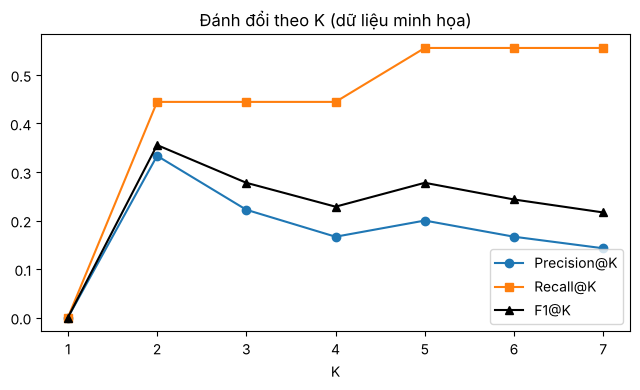

In [18]:
# Biểu đồ P@K, R@K, F1@K khi K thay đổi
Ks = range(1, 8)
mean_p, mean_r, mean_f = [], [], []
for K in Ks:
    vals = np.array([prf_at_k(recs[u], rel[u], K) for u in recs])
    mean_p.append(vals[:, 0].mean()); mean_r.append(vals[:, 1].mean()); mean_f.append(vals[:, 2].mean())

plt.figure(figsize=(6.5, 4))
plt.plot(Ks, mean_p, 'o-', label='Precision@K')
plt.plot(Ks, mean_r, 's-', label='Recall@K')
plt.plot(Ks, mean_f, '^-', label='F1@K', color='k')
plt.xlabel('K'); plt.legend(); plt.title('Đánh đổi theo K (dữ liệu minh họa)'); plt.tight_layout(); plt.show()

**Tóm tắt**
- Correlation chuẩn hóa về $[-1,1]$, covariance phụ thuộc đơn vị.
- $R^2$ cho biết tỷ lệ phương sai của $y$ được mô hình giải thích.
- $F_1$ cân bằng Precision và Recall; trong gợi ý, tăng $K$ thường làm Recall tăng nhưng Precision giảm.